# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name: Saba Noor**
- **Student ID: 023-24-0278**
- **Section: H**
- **GitHub: https://github.com/SABANOOR1/Machine-Learning**
- **Kaggle: https://www.kaggle.com/sabajaffar**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/code/emineyetm/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [63]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import pandas as pd
from sklearn.model_selection import train_test_split
df=pd.read_csv("Telco-Customer-Churn.csv")
df.dtypes

df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")
df["TotalCharges"]=df["TotalCharges"].fillna(df["TotalCharges"].median())

df=df.drop(columns=["customerID"])

df["Churn"]=df["Churn"].map({"Yes": 1,"No":0})

In [64]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
df=pd.get_dummies(df, drop_first=True)
y=df["Churn"]
X=df.drop("Churn", axis=1)
X_train, X_test, y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
df.head(5)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [65]:
# YOUR CODE HERE — unscaled linear SVM
from sklearn.metrics import accuracy_score, f1_score
import time

start = time.time()
y_pred_raw = svm_raw.predict(X_test)
raw_time = time.time() - start

print("Unscaled Linear SVM")
print("Accuracy:", accuracy_score(y_test, y_pred_raw))
print("F1-score:", f1_score(y_test, y_pred_raw))
print("Prediction time:", raw_time)


Unscaled Linear SVM
Accuracy: 0.7906316536550745
F1-score: 0.5203252032520326
Prediction time: 0.0799856185913086


In [66]:
# YOUR CODE HERE — scaled linear SVM
start = time.time()
y_pred_scaled = svm_scaled.predict(X_test_s)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
scaled_time = time.time() - start

print("\nScaled Linear SVM")
print("Accuracy:", accuracy_score(y_test, y_pred_scaled))
print("F1-score:", f1_score(y_test, y_pred_scaled))
print("Prediction time:", scaled_time)


Scaled Linear SVM
Accuracy: 0.7892122072391767
F1-score: 0.5714285714285714
Prediction time: 0.11418795585632324


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer: The unscaled Linear SVM achieved slightly higher accuracy of 79.06%, while the scaled model achieved 78.92%. However, the scaled model performed better in terms of F1-score, increasing from 52.03% to 57.14%. This means that scaling helped the model balance its predictions for customers who churn and those who do not. The unscaled model also had a shorter prediction time of 0.075 seconds, compared to 0.104 seconds for the scaled model.*

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Linear SVM tries to find the best decision boundary to separate customers who churn from those who stay. When features have different scales, features with larger numerical values can have a greater influence on the decision boundary and margin. Scaling puts the features on a similar scale, helping the model make a more balanced separation. In my results, scaling slightly reduced accuracy but improved the F1-score, suggesting that it helped the model identify churn cases more effectively.*

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer: From this point onward, I will use the scaled version for the remaining SVM models because it achieved a higher F1-score of 57.14%, compared to 52.03% for the unscaled model. Although its accuracy was slightly lower, the F1-score is particularly useful for this customer churn project because it considers both precision and recall. This makes it a helpful measure when identifying customers who are likely to leave the service.*


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [67]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

kernels = ["linear", "rbf", "poly"]
models = {}
results = []

for kernel in kernels:
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    models[kernel] = model

    results.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "Support Vectors": model.support_.shape[0]
    })

print("All three SVC models have been trained successfully!")


All three SVC models have been trained successfully!


In [68]:
# YOUR CODE HERE — comparison table

import pandas as pd

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))


,Kernel,Accuracy,Precision,Recall,F1-score,Support Vectors
0,linear,0.7892,0.6207,0.5294,0.5714,2569
1,rbf,0.7928,0.6444,0.4893,0.5562,2661
2,poly,0.7892,0.6421,0.4652,0.5395,2739


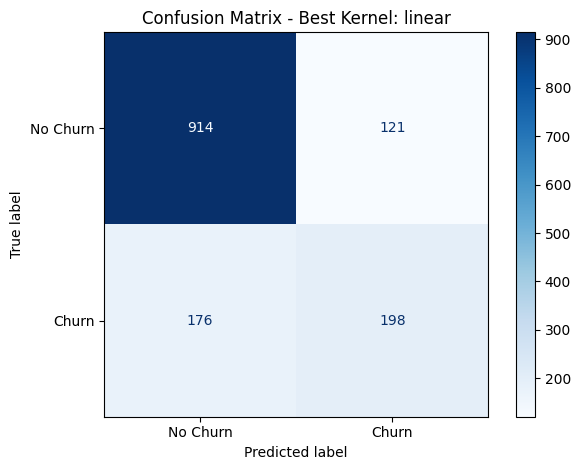

Best kernel based on F1-score: linear


In [69]:
# YOUR CODE HERE — confusion matrix for the best kernel

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_kernel = comparison_df.loc[0, "Kernel"]
best_model = models[best_kernel]

y_pred_best = best_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred_best)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - Best Kernel: {best_kernel}")
plt.tight_layout()
plt.show()

print(f"Best kernel based on F1-score: {best_kernel}")


**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer: The linear kernel achieved the highest F1-score of 0.5714 (57.14%), followed by the RBF kernel at 0.5562 (55.62%) and the polynomial kernel at 0.5395 (53.95%). This result slightly surprised me because I expected the nonlinear kernels, especially RBF, to capture more complex patterns in customer churn. However, the linear kernel performed better on this dataset, suggesting that a more complex decision boundary did not necessarily improve the model's ability to identify customers who might churn.*

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer: for RBF and 2,569 for the linear kernel. A high support-vector count means the model relies on more training examples to define its decision boundary. This may indicate that separating the two classes is more challenging for that model. However, having more support vectors does not automatically mean the model is better or that it is overfitting.*

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer: I would carry forward the linear kernel for hyperparameter tuning because it achieved the highest F1-score of 0.5714, compared with 0.5562 for RBF and 0.5395 for polynomial. It also achieved a recall of 0.5294, higher than RBF at 0.4893 and polynomial at 0.4652. Since identifying customers who are likely to churn is important in this project, the linear kernel is the strongest starting point based on these results. I would tune its parameters to check whether its F1-score and recall can be improved further.*


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [70]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

explained_variance = pca.explained_variance_ratio_
total_variance = explained_variance.sum()

print("Variance ratio of component 1:", round(explained_variance[0], 4))
print("Variance ratio of component 2:", round(explained_variance[1], 4))
print("Total variance ratio:", round(total_variance, 4))
print(f"Total variance explained: {total_variance * 100:.2f}%")


Variance ratio of component 1: 0.3325
Variance ratio of component 2: 0.1198
Total variance ratio: 0.4523
Total variance explained: 45.23%


In [71]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection

from sklearn.svm import SVC

C_values = [0.01, 1, 100]

models_pca = {}

for c in C_values:
    model = SVC(kernel="rbf", C=c, random_state=42)
    model.fit(X_train_pca, y_train)

    models_pca[c] = model

    print(f"C = {c}")
    print("Number of support vectors:", model.support_.shape[0])
    print("-" * 35)


C = 0.01
Number of support vectors: 2997
-----------------------------------
C = 1
Number of support vectors: 2659
-----------------------------------
C = 100
Number of support vectors: 2631
-----------------------------------


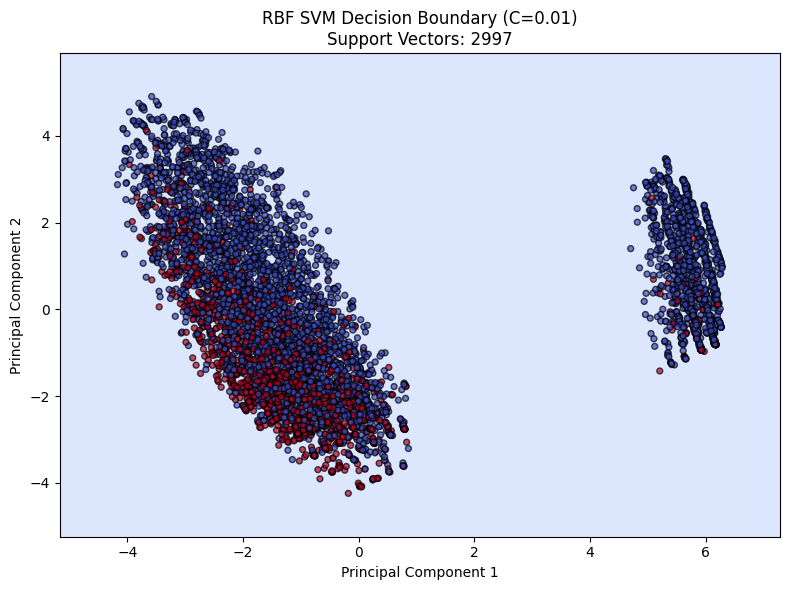

In [ ]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)

import numpy as np
import matplotlib.pyplot as plt

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

for c in C_values:
    model = models_pca[c]

    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points)
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

    plt.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="black",
        s=18,
        alpha=0.7
    )

    plt.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=1)

    plt.title(
        f"RBF SVM Decision Boundary (C={c})\n"
        f"Support Vectors: {model.support_.shape[0]}"
    )
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.tight_layout()
    plt.show()


The PCA plots show how the SVM separates churners from non-churners using two principal components. Changing the value of C affects how strongly the model penalizes classification errors and can change the decision boundary. However, these plots show only a two-dimensional projection of the data, so they may not represent the model's full performance.

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer: As the value of C increases from 0.01 to 100, the model penalizes classification errors more strongly. With a small C, the decision boundary generally favors a wider margin and may appear smoother. With a large C, the model tries harder to classify the training points correctly, which can produce a more flexible boundary.*

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer: The number of support vectors can change as C increases because the model adjusts its decision boundary and margin to classify the training points. A smaller C allows more margin violations, while a larger C penalizes them more strongly. The number of support vectors may increase or decrease, so it does not have to follow one fixed pattern. I compared the support-vector counts from my three models to see how they changed in my experiment.*

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer: The model with C = 100 may be overfitting if its decision boundary bends around individual training points or creates small, irregular regions. This could mean the model is fitting noise in the training data rather than learning general patterns.
The model with C = 0.01 may be underfitting if its boundary is too simple to separate the two classes effectively. However, a small C does not automatically mean underfitting. I would use the actual plots to decide which model shows these patterns. The model with C = 1 may provide a reasonable middle ground if its boundary separates the classes without excessive complexity.*

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer: The 2-D plot is only an approximation because PCA reduces all the original features to just two principal components. These components capture only part of the variation in the original dataset, so some information about customer behavior is lost. The SVM is trained on this reduced representation rather than the complete feature set.
As a result, the plot can be misleading because customers who appear close together in two dimensions may be different in the original feature space. The decision boundary shown may also differ from the boundary learned using all the original features. Therefore, the visualization helps me understand how the model separates the classes, but it does not fully represent the SVM's behavior on the complete dataset.*


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [ ]:
# YOUR CODE HERE — define param_grid and run GridSearchCV

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "gamma": [0.001, 0.01, 0.1, 1]
}

gs = GridSearchCV(
    estimator=SVC(kernel="rbf", random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

gs.fit(X_train_scaled, y_train)

print("Best parameters:", gs.best_params_)
print("Best cross-validation F1-score:", round(gs.best_score_, 4))


In [ ]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cv_results = pd.DataFrame(gs.cv_results_)

display(
    cv_results[
        ["param_C", "param_gamma", "mean_test_score", "std_test_score", "rank_test_score"]
    ].sort_values("rank_test_score")
)

heatmap_data = cv_results.pivot(
    index="param_C",
    columns="param_gamma",
    values="mean_test_score"
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu"
)

plt.title("GridSearchCV: Mean Cross-Validated F1-score")
plt.xlabel("Gamma")
plt.ylabel("C")
plt.tight_layout()
plt.show()


In [ ]:
# YOUR CODE HERE — refit best estimator, evaluate on test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

best_svm = gs.best_estimator_

y_pred = best_svm.predict(X_test_scaled)

print("Best parameters:", gs.best_params_)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Best RBF SVM - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()


The heatmap shows that C = 10 and gamma = 0.001 gave the highest cross-validation F1-score of 0.5857. The combination C = 10 and gamma = 0.01 performed almost as well. Some parameter combinations produced an F1-score of zero, showing that selecting suitable hyperparameters is important.

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer: The GridSearchCV results show that the best hyperparameter combination for the RBF SVM model is **C = 10** and **gamma = 0.001**. This combination achieved a mean cross-validation F1-score of **0.5857** across five folds.

The value of C = 10 gives the model a stronger penalty for classification errors, while gamma = 0.001 allows the influence of individual training samples to extend over a wider area. Together, these values provided the best balance between precision and recall among the 16 combinations tested.*

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer: The best result came from C = 10 and gamma = 0.001, with a cross-validation F1-score of 0.5857. The combination C = 10 and gamma = 0.01 performed almost as well. The results show that choosing the right hyperparameters is important, as some combinations produced very low F1-scores.*

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:The cross-validation F1-score was 0.5857, while the test F1-score was 0.5820. Since the difference is small, the model performs consistently on unseen data, with no clear sign of severe overfitting.*

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer: The tuned model improved the F1-score from 0.5562 to 0.5820. Accuracy, precision, and recall also improved slightly. I think tuning was worthwhile because it improved the model's ability to identify customers likely to leave, although the overall improvement was moderate.*


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [ ]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
from sklearn.svm import SVC
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

svm_default = SVC(
    kernel="rbf",
    C=10,
    gamma=0.001,
    class_weight=None
)

svm_balanced = SVC(
    kernel="rbf",
    C=10,
    gamma=0.001,
    class_weight="balanced"
)

svm_default.fit(X_train_scaled, y_train)
svm_balanced.fit(X_train_scaled, y_train)

pred_default = svm_default.predict(X_test_scaled)
pred_balanced = svm_balanced.predict(X_test_scaled)

results = pd.DataFrame({
    "Model": ["Default", "Balanced"],
    "Precision": [
        precision_score(y_test, pred_default, zero_division=0),
        precision_score(y_test, pred_balanced, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_default, zero_division=0),
        recall_score(y_test, pred_balanced, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, pred_default, zero_division=0),
        f1_score(y_test, pred_balanced, zero_division=0)
    ]
})

print(results.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_default,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Default SVM")

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_balanced,
    display_labels=["No Churn", "Churn"],
    cmap="Oranges",
    ax=axes[1]
)
axes[1].set_title("Balanced SVM")

plt.tight_layout()
plt.show()

In [ ]:
# YOUR CODE HERE — ROC or Precision-Recall curve
from sklearn.metrics import roc_curve, roc_auc_score

scores = svm_balanced.decision_function(X_test_scaled)

fpr, tpr, thresholds = roc_curve(y_test, scores)
auc = roc_auc_score(y_test, scores)

default_idx = abs(thresholds).argmin()

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Balanced SVM (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.scatter(
    fpr[default_idx],
    tpr[default_idx],
    s=80,
    label="Default decision threshold"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Balanced RBF SVM")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"ROC-AUC: {auc:.4f}")

The ROC curve illustrates the trade-off between identifying actual churners and incorrectly flagging loyal customers at different decision thresholds. A curve closer to the top-left corner generally indicates better discrimination. The marked point represents the model's default decision threshold.

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer: After using class_weight='balanced', precision decreased from 0.6502 to 0.4575, while recall increased from 0.5267 to 0.8209. The model now identifies more actual churners, but it also incorrectly flags more loyal customers. The F1-score improved slightly from 0.5820 to 0.5876.*

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer: For a telecom company, missing an actual churner (false negative) can be costly because the company loses the chance to offer them a retention deal before they leave. However, wrongly targeting loyal customers (false positives) also wastes marketing resources.I would recommend the balanced model if retaining at-risk customers is the main priority, because its recall of 82.09% means it catches more actual churners. The company should monitor the cost of unnecessary retention offers, since its precision is lower at 45.75%.*

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer: SVM does not directly provide churn probabilities by default. For the ROC curve, I used decision_function() to obtain continuous decision scores, which can rank customers by how strongly the model predicts churn. These scores are not actual probabilities.I did not need to enable probability=True for this method. If actual probability estimates were required, I could set probability=True in SVC(), then use predict_proba(). This adds computational cost and uses probability calibration internally.*


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [ ]:
# YOUR CODE HERE — cross-model comparison table
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5]
    },
    scoring="f1",
    cv=5,
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest (tuned)": rf_grid.best_estimator_,
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM (balanced RBF)": SVC(
        kernel="rbf",
        C=10,
        gamma=0.001,
        class_weight="balanced"
    )
}

results = []

for name, model in models.items():
    if name in ["Logistic Regression", "KNN", "SVM (balanced RBF)"]:
        Xtr, Xte = X_train_scaled, X_test_scaled
    else:
        Xtr, Xte = X_train, X_test

    model.fit(Xtr, y_train)
    predictions = model.predict(Xte)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

comparison = pd.DataFrame(results).set_index("Model")
print(comparison.round(4))

print("\nBest Random Forest parameters:", rf_grid.best_params_)

In [ ]:
# YOUR CODE HERE — bar chart of F1-score across models
plt.figure(figsize=(9, 5))

comparison["F1-score"].sort_values().plot(
    kind="bar",
    rot=30
)

plt.title("F1-score Comparison Across Five Models")
plt.xlabel("Model")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("Best F1-score:", comparison["F1-score"].idxmax())
print("Best recall:", comparison["Recall"].idxmax())

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer: Logistic Regression achieved the highest F1-score of 0.6092, while the balanced SVM achieved the highest recall of 0.8209. They are not the same model. Logistic Regression offers a better balance between precision and recall, while the balanced SVM identifies more actual churners.*

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer: In my results, the balanced SVM achieved high recall, but its accuracy was only 0.6941 and its precision was 0.4575. Logistic Regression performed better in accuracy, precision, and F1-score while also being computationally simpler. Therefore, the extra cost of SVM may not be worthwhile unless identifying as many potential churners as possible is the company's main priority.*

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer: I would recommend Logistic Regression for production. It achieved the highest accuracy (0.8070) and F1-score (0.6092), with precision of 0.6584 and recall of 0.5668. This provides a good balance between identifying potential churners and avoiding unnecessary retention offers. If the company considers missing a churner especially costly, it should also consider the balanced SVM because of its much higher recall.*


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [ ]:
# YOUR CODE HERE — generate and save svm_predictions.csv
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

final_model = LogisticRegression(max_iter=2000, random_state=42)
final_model.fit(X_train_scaled, y_train)

y_pred = final_model.predict(X_test_scaled)
churn_probability = final_model.predict_proba(X_test_scaled)[:, 1]

predictions_df = pd.DataFrame({
    "true_label": y_test.to_numpy(),
    "predicted_label": y_pred,
    "churn_probability": churn_probability
})

predictions_df.to_csv("svm_predictions.csv", index=False)

print("Predictions saved to svm_predictions.csv")
print(predictions_df.head())

**Executive Summary**

*Your summary here:In this lab, I compared five machine learning models to predict customer churn and selected Logistic Regression as the final model. It achieved the highest F1-score of 0.6092, an accuracy of 80.70%, precision of 65.84%, and recall of 56.68%. These results provide a reasonable balance between identifying customers likely to leave and avoiding unnecessary retention offers. In Part 5, the balanced SVM achieved a much higher recall of 82.09%, but its precision was lower at 45.75%, meaning more loyal customers could be incorrectly flagged. I chose Logistic Regression because it achieved a better overall balance and was less computationally demanding. One limitation is that the model may not capture every factor influencing customer churn, and its performance may change on new customer data.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer: The most surprising result was that the balanced SVM achieved a recall of 82.09%, much higher than Logistic Regression's 56.68%, but its precision was considerably lower. This showed how handling class imbalance can help detect more churners while also increasing false positives.*

(b) If you had one more hour, what would you try next?

*Your answer: I would try SMOTE to address class imbalance in the training data and compare its results with the balanced SVM and Logistic Regression. I would check whether it improves recall without reducing precision too much. I would also test the model on new data if available.*
